<a href="https://colab.research.google.com/github/desireesosa/SimulacionII/blob/main/MCMC_SIR_Modelo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

| **Asignatura** | **Estudiante** | **Actividad** |
| :---: | :---: | :---: |
| Simulación II | Desiree Salim Sosa Gomez | Modelo SIR con Metropolis |

---

<h1> Modelo SIR mediante el Algoritmo Metropolis-Hastings </h1>

<h3> Problemas y Datos.</h3>
<p> En el trabajo <i>The inverse problem of a dynamical system solved with genetic algorithms</i>, se aborda la estimación de parámetros en sistemas dinámicos desde la perspectiva de los problemas inversos, donde un problema inverso consiste en determinar los factores causales o parámetros internos de un modelo matemático a partir de un conjunto de observaciones experimentales o series de tiempo. </p>

> **Caso de estudio**

> Se utiliza el conjunto de datos de la epidemia de Influenza en un internado británico acontecida en enero de 1978, reportada originalmente por **Murray (2002)** y sintetizada en la Tabla 1 de la Sección 2.2 del artículo. El experimento registra el número de alumnos infectados activos $I(t)$ durante un periodo de 14 días en una población escolar de $N = 763$ estudiantes masculinos.

> Se conocen las condiciones iniciales exactas del sistema:
* $I(0) = 1$ infectado inicial
* $S(0) = 762$ alumnos susceptibles
* $R(0) = 0$ al inicio del brote

> La población se asume estrictamente cerrada y constante, por lo que:

$$N = S(t) + I(t) + R(t) = 763 \quad \text{para todo tiempo } t$$






La dinámica del brote se describe mediante el modelo epidemiológico SIR tradicional:

$$\frac{dS}{dt} = -a S I, \quad \frac{dI}{dt} = a S I - b I, \quad \frac{dR}{dt} = b I$$

donde $a$ representa la tasa de transmisión y $b$ la tasa de recuperación.

Mientras que en el artículo de referencia el par óptimo $(a, b)$ se determina minimizando la distancia $L_1$ entre la solución numérica y las observaciones mediante un algoritmo genético (AG), en este cuaderno planteamos una **solución bayesiana**.

Construimos la distribución posterior de los parámetros mediante el **algoritmo de Metropolis-Hastings**, lo cual nos permite estimar los parámetros $a$ y $b$ cuantificando la incertidumbre asociada a la predicción y al ruido de medición.

In [ ]:
import importlib.util
import subprocess
import sys

# Verificación e instalación de dependencias necesarias
for pkg in ["arviz", "corner"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg])

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import arviz as az
import corner

plt.rcParams.update({
    "figure.figsize": (8.5, 4.2),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "grid.alpha": 0.25
})

#Tabla 1
t_obs = np.arange(0, 15)
i_obs = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

#Condiciones iniciales
N = 763.0
I0 = float(i_obs[0])
S0 = N - I0
R0_init = 0.0
y0 = [S0, I0, R0_init]


t_fit = t_obs[1:]
i_fit = i_obs[1:]
n_obs = len(i_fit)

<h3> Integración numérica del sistema dinámico. </h3>

Definimos el sistema de EDOs no lineales. Se utiliza el integrador `odeint` para resolver la trayectoria de $I(t)$ dados los parámetros $a$ y $b$.

In [ ]:
def sir_ode(y, t, a, b):
    S, I, R = y
    ds = -a * S * I
    di = a * S * I - b * I
    dr = b * I
    return [ds, di, dr]

def simular_I(a, b, t_eval):
    sol = odeint(sir_ode, y0, t_eval, args=(a, b))
    return sol[:, 1]

<h3> Modelo Estocástico.</h3>

Para la verosimilitud suponemos que los datos observados $I_{\text{obs}}(t)$ difieren de la solución determinista $I_{\text{pred}}(t)$ debido a un error Gaussiano independiente e idénticamente distribuido con varianza constante $\sigma^2$:

$$I_{\text{obs}}(t) \sim \mathcal{N}\left(I_{\text{pred}}(t; a, b), \sigma^2\right)$$

Dado que los parámetros $a$, $b$ y $\sigma$ son estrictamente positivos y operan en escalas de magnitud distintas, realizamos la exploración MCMC sobre el espacio de variables transformadas $z$:

$$z_0 = \log(1000 a), \quad z_1 = \log(b), \quad z_2 = \log(\sigma)$$

Al pasar del espacio original al espacio logarítmico, aplicamos la corrección por la matriz Jacobiana $|\mathbf{J}| = a \cdot b \cdot \sigma$ en la densidad posterior.

Asumiendo priors independientes sobre los parámetros en el rango de búsqueda definido por el artículo ($a, b \in (0, 1)$), la función de log-posterior resulta:

In [ ]:
def log_posterior_z(z):

    # Restricciones
    if z[0] >= np.log(1000.0) or z[1] >= 0.0 or not (np.log(0.1) < z[2] < np.log(200.0)):
        return -np.inf

    a = np.exp(z[0]) / 1000.0
    b = np.exp(z[1])
    sigma = np.exp(z[2])

    # Resolver modelo para t = 1..14
    i_pred = simular_I(a, b, t_fit)

    residuos = i_fit - i_pred
    log_likelihood = -0.5 * n_obs * np.log(2.0 * np.pi * sigma**2) - np.sum(residuos**2) / (2.0 * sigma**2)

    log_prior_jacobiano = 2.0 * (z[0] + z[1])

    return log_likelihood + log_prior_jacobiano

<h3> Muestreador MCMC.</h3>

Para explorar la distribución posterior en el espacio tridimensional $z$, implementamos el algoritmo de Metropolis-Hastings aleatorio (Random Walk Metropolis). En cada paso $k$, se propone un nuevo estado $z^*$ a partir de una distribución Gaussiana simétrica $q(z^* \mid z^{(k-1)}) = \mathcal{N}(z^{(k-1)}, \mathbf{\Sigma}_{\text{prop}})$.

La razón de aceptación de Metropolis en escala logarítmica viene dada por:$$\log \alpha = \log p(z^* \mid \mathbf{I}_{\text{obs}}) - \log p(z^{(k-1)} \mid \mathbf{I}_{\text{obs}})$$

Si $\log U(0,1) < \log \alpha$, la propuesta es aceptada y $z^{(k)} = z^*$; de lo contrario, se rechaza y la cadena permanece en su estado anterior ($z^{(k)} = z^{(k-1)}$).

In [ ]:
def ejecutar_metropolis(log_target, z_init, n_iter, step_sizes):
    d = len(z_init)
    cadenas = np.zeros((n_iter, d))
    cadenas[0] = z_init

    log_p_actual = log_target(z_init)
    aceptados = 0

    for k in range(1, n_iter):
        z_prop = cadenas[k-1] + np.random.normal(0, step_sizes, size=d)
        log_p_prop = log_target(z_prop)

        if np.log(np.random.uniform(0, 1)) < (log_p_prop - log_p_actual):
            cadenas[k] = z_prop
            log_p_actual = log_p_prop
            aceptados += 1
        else:
            cadenas[k] = cadenas[k-1]

    return cadenas, aceptados / n_iter

#Configuración del muestreo MCMC
n_cadenas = 4
n_pasos = 20000
burn_in = 5000
pasos_propuesta = np.array([0.025, 0.025, 0.04])

#Puntos de partida dispersos para evaluar
inicios = [
    np.array([np.log(2.18), np.log(0.4485), np.log(10.0)]),
    np.array([np.log(1.20), np.log(0.2500), np.log(20.0)]),
    np.array([np.log(3.50), np.log(0.6000), np.log(5.0)]),
    np.array([np.log(1.80), np.log(0.3500), np.log(15.0)])
]

muestras_z = []
print("Ejecutando cadenas de Markov Metropolis-Hastings...")
start_time = time.time()

for i, z0 in enumerate(inicios):
    c, alpha = ejecutar_metropolis(log_posterior_z, z0, n_pasos, pasos_propuesta)
    muestras_z.append(c[burn_in:])
    print(f" Cadena {i+1} completada. Tasa de aceptación: {alpha:.1%}")

print(f"Muestreo finalizado en {time.time() - start_time:.2f} segundos.")

Ejecutando cadenas de Markov Metropolis-Hastings...
 Cadena 1 completada. Tasa de aceptación: 53.5%
 Cadena 2 completada. Tasa de aceptación: 55.7%
 Cadena 3 completada. Tasa de aceptación: 53.0%
 Cadena 4 completada. Tasa de aceptación: 54.1%
Muestreo finalizado en 73.31 segundos.


### Inferencia Estadística y Diagnósticos

Transformamos las cadenas de Markov del espacio transformado $z$ de vuelta al espacio de parámetros físicos $(a, b, \sigma)$ y las formateamos como un objeto `InferenceData` de ArviZ. Esto nos permite evaluar la convergencia mediante:

* El factor $\hat{R}$ de Gelman-Rubin
* El tamaño efectivo de muestra ($ESS$)

In [ ]:
cadenas_fisicas = []
for c in muestras_z:
    a_m = np.exp(c[:, 0]) / 1000.0
    b_m = np.exp(c[:, 1])
    s_m = np.exp(c[:, 2])
    cadenas_fisicas.append(np.column_stack([a_m, b_m, s_m]))

arr_cadenas = np.array(cadenas_fisicas)

idata = az.from_dict(
    posterior={
        "a": arr_cadenas[:, :, 0],
        "b": arr_cadenas[:, :, 1],
        "sigma": arr_cadenas[:, :, 2]
    }
)

# Resumen numérico con intervalos de alta densidad (HDI) al 95%
resumen = az.summary(idata, hdi_prob=0.95)
display(resumen[["mean", "sd", "hdi_2.5%", "hdi_97.5%", "r_hat", "ess_bulk"]])

,mean,sd,hdi_2.5%,hdi_97.5%,r_hat,ess_bulk
a,0.003,0.000,0.002,0.003,1.00,6980.0
b,0.476,0.021,0.437,0.518,1.00,2165.0
sigma,21.436,4.702,13.580,31.487,1.02,259.0


#### Inferencia sobre el Número Reproductivo Básico $R_0$

Propagamos las distribuciones posteriores marginales de $a$ y $b$ para calcular la distribución posterior del número reproductivo básico:

$$R_0 = \frac{a N}{b}$$

In [ ]:
a_flat = idata.posterior["a"].values.flatten()
b_flat = idata.posterior["b"].values.flatten()
r0_flat = (a_flat * N) / b_flat

print(f"\nEstimación Bayesiana de R0:")
print(f" Media posterior: {np.mean(r0_flat):.3f}")
print(f" Desviación estándar: {np.std(r0_flat):.3f}")
print(f" Intervalo HDI 95%: [{np.percentile(r0_flat, 2.5):.3f}, {np.percentile(r0_flat, 97.5):.3f}]")


Estimación Bayesiana de R0:
 Media posterior: 4.127
 Desviación estándar: 0.176
 Intervalo HDI 95%: [3.781, 4.479]


## Diagnóstico Visual y Resultados Gráficos

#### Trazas de Muestreo (`az.plot_trace`)

Evaluamos la superposición y estacionariedad de las cuatro cadenas de Markov independientes:

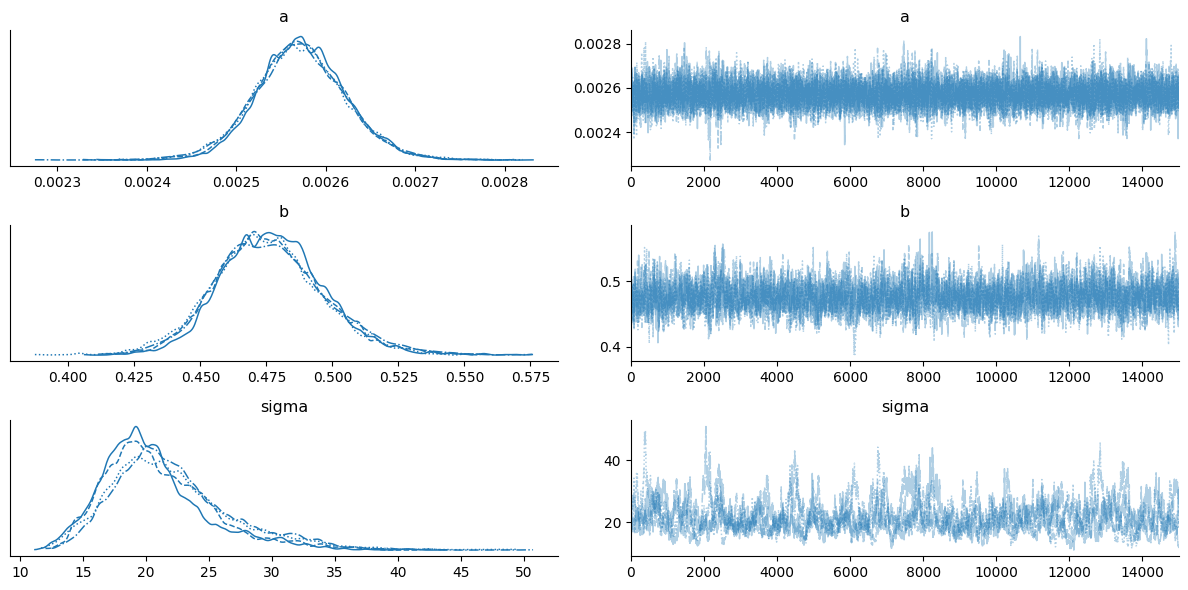

In [ ]:
az.plot_trace(idata, var_names=["a", "b", "sigma"])
plt.tight_layout()
plt.show()

#### Ajuste Epidemiológico y Propagación de Incertidumbre

Extraemos 150 combinaciones de parámetros de la distribución posterior para simular la envolvente de incertidumbre sobre la curva de enfermos activos $I(t)$:

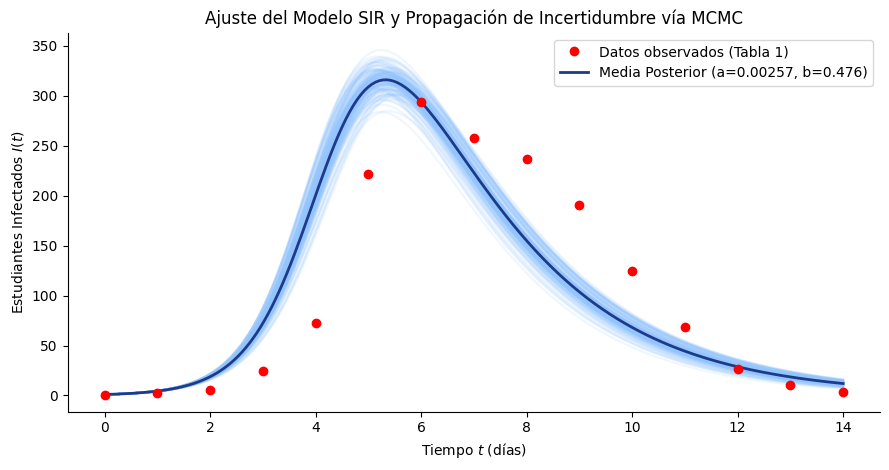

In [ ]:
t_linea = np.linspace(0, 14, 200)
submuestra_idx = np.random.choice(len(a_flat), size=150, replace=False)

plt.figure(figsize=(9, 4.8))

# Graficar abanico de incertidumbre posterior
for idx in submuestra_idx:
    i_sim = simular_I(a_flat[idx], b_flat[idx], t_linea)
    plt.plot(t_linea, i_sim, color="#93c5fd", alpha=0.15)

# Trayectoria basada en la media posterior
a_media, b_media = np.mean(a_flat), np.mean(b_flat)
i_promedio = simular_I(a_media, b_media, t_linea)

plt.plot(t_obs, i_obs, 'ro', label='Datos observados (Tabla 1)', markersize=6, zorder=5)
plt.plot(t_linea, i_promedio, color="#1e3a8a", lw=2, label=f'Media Posterior (a={a_media:.5f}, b={b_media:.3f})')

plt.xlabel('Tiempo $t$ (días)')
plt.ylabel('Estudiantes Infectados $I(t)$')
plt.title('Ajuste del Modelo SIR y Propagación de Incertidumbre vía MCMC')
plt.legend()
plt.tight_layout()
plt.show()